# 03 – Phân tích khám phá (EDA): Kỹ năng CNTT nào VTI Academy nên dạy?
**Người ra quyết định (stakeholder duy nhất):** *Quản lý đào tạo (bộ phận thiết kế chương trình)* của VTI Academy.
Mỗi phần dưới đây trả lời **một quyết định** của họ.

**Làm sạch (notebook 02) khác EDA (notebook này) thế nào?**
- *Làm sạch* = sửa dữ liệu cho đúng: bỏ trùng, đổi kiểu, xử lý giá trị vô lý, đổi tên cột → ra file `clean_data.xlsx`.
- *EDA* (Exploratory Data Analysis – phân tích khám phá) = **đọc** dữ liệu đã sạch để đếm, so sánh, vẽ biểu đồ, kiểm định → tìm câu trả lời. **Notebook này không sửa dữ liệu nữa**, chỉ bắt đầu từ `clean_data.xlsx`.

**4 câu hỏi (theo Phần D của kế hoạch):**
| | Câu hỏi | Kỹ thuật |
|---|---|---|
| Q1 | Ngôn ngữ nào làm **khóa lõi**, ngôn ngữ nào đáng **mở khóa mới**? | Tần suất, %, đang dùng vs muốn dùng, nhu cầu tuyển dụng |
| Q2 | Dạy **database** nào, ưu tiên **SQL quan hệ hay NoSQL**? | Tần suất, %, chênh lệch muốn − đang dùng |
| Q3 | Chuẩn hóa **IDE** nào cho phòng lab? | Tần suất, % (chỉ khảo sát) |
| Q4 | Đầu tư **kỹ năng mới nổi** nào, nhắm **nhóm học viên** nào? | Tỷ lệ tăng muốn/đang dùng, so tuyển dụng VN, tương quan Spearman, Chi-bình-phương + Cramér's V |

**3 quy tắc tính toán (ghi trong sheet `readme`):**
1. % khảo sát = số người chọn kỹ năng ÷ **số người đã trả lời câu đó** (cột `answered_*` = 1), *không* chia cho 11.398.
2. % tuyển dụng = số tin nhắc kỹ năng ÷ **tổng số tin (405)**; ghi kèm tỷ lệ tin có nhắc kỹ năng (`has_any_skill`).
3. So sánh 2 nguồn bằng **thứ hạng**, không bằng % tuyệt đối; **bỏ Node.js** khi so (khảo sát xếp Node.js vào framework, tin tuyển dụng tính vào JavaScript).

## 0. Chuẩn bị

### 0.1 Kiểm tra thư viện (không cài gì thêm)
**🎯 Mục tiêu:** Chắc chắn máy có `pandas`, `numpy`, `matplotlib`, `scipy`, `openpyxl`.

**❓ Vì sao làm bước này:** Notebook này **không gọi pip** (không đụng vào hệ thống). Nếu thiếu thư viện thì báo rõ tên để bạn tự cài, thay vì lỗi khó hiểu giữa chừng.

**🧠 Cách suy nghĩ:** Thử `import` từng thư viện; được thì thôi, không được thì ghi vào danh sách thiếu.

**🔁 Dùng khi nào (trường hợp khác):** Đầu mọi notebook gửi cho người khác chạy.

In [1]:
import importlib
thieu = []
for ten in ["pandas", "numpy", "matplotlib", "scipy", "openpyxl"]:
    try:
        importlib.import_module(ten)      # thử nạp thư viện
    except ImportError:
        thieu.append(ten)                 # không nạp được -> ghi lại
print("Đủ thư viện." if not thieu else f"THIẾU: {thieu} -> hãy cài (vd: pip install {' '.join(thieu)}) rồi chạy lại.")

Đủ thư viện.


### 0.2 Import & cài đặt hiển thị
**🎯 Mục tiêu:** Nạp công cụ, tạo thư mục `figures/` để lưu biểu đồ.

**❓ Vì sao làm bước này:** Gom mọi `import` ở một chỗ → dễ kiểm tra. Ảnh lưu sẵn để dán vào slide.

**🧠 Cách suy nghĩ:** Đường dẫn **tương đối** (`figures/`, `clean_data.xlsx`) → mở thư mục FINAL PROJECT trong VS Code là chạy được, không phụ thuộc máy.

**🔁 Dùng khi nào (trường hợp khác):** Mọi dự án có nhiều người cùng chạy.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 200)
plt.rcParams["font.family"] = "DejaVu Sans"        # font có dấu tiếng Việt
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
HINH = Path("figures"); HINH.mkdir(exist_ok=True)  # thư mục lưu ảnh

## 1. Đọc dữ liệu sạch & tổng quan

### 1.1 Đọc 5 sheet của `clean_data.xlsx`
**🎯 Mục tiêu:** Đưa 5 sheet vào 5 bảng (DataFrame = bảng dữ liệu trong Python).

**❓ Vì sao làm bước này:** Đây là điểm bắt đầu của EDA – dữ liệu đã được làm sạch ở notebook 02.

**🧠 Cách suy nghĩ:** `sheet_name=None` đọc **tất cả** sheet một lần, trả về từ điển {tên sheet: bảng}.

**🔁 Dùng khi nào (trường hợp khác):** File Excel nhiều sheet bất kỳ.

In [3]:
du_lieu = pd.read_excel("clean_data.xlsx", sheet_name=None)   # đọc mọi sheet
for ten, bang in du_lieu.items():
    print(f"{ten:<20} {bang.shape[0]:>8,} dòng x {bang.shape[1]} cột")

respondents = du_lieu["survey_respondents"]   # 1 dòng = 1 người trả lời
survey_skills = du_lieu["survey_skills"]      # 1 dòng = 1 người x 1 kỹ năng x 1 trạng thái
jobs = du_lieu["job_postings"]                # 1 dòng = 1 tin tuyển dụng
job_skills = du_lieu["job_skills"]            # 1 dòng = 1 tin x 1 kỹ năng
du_lieu["readme"]

readme                      8 dòng x 3 cột
survey_respondents     11,398 dòng x 33 cột
survey_skills         382,659 dòng x 5 cột
job_postings              405 dòng x 8 cột
job_skills              1,185 dòng x 4 cột


,sheet,mo_ta,khoa_noi
0,survey_respondents,1 dòng = 1 người trả lời khảo sát Stack Overfl...,respondent_id
1,survey_skills,1 dòng = 1 người x 1 kỹ năng x 1 trạng thái (w...,respondent_id -> survey_respondents
2,job_postings,1 dòng = 1 tin tuyển dụng từ 123job.vn (đã chu...,job_id
3,job_skills,1 dòng = 1 tin x 1 kỹ năng nhắc đến trong tin ...,job_id -> job_postings
4,LUU_Y_mau_so,Khi tính % trong khảo sát: chia cho số người đ...,NaN
5,LUU_Y_nodejs,"Trong tin tuyển dụng, Node.js được tính vào Ja...",NaN
6,LUU_Y_ide,IDE chỉ có trong khảo sát (tin tuyển dụng hầu ...,NaN
7,LUU_Y_mau,Kỹ năng trong tin tuyển dụng được rút bằng so ...,NaN


### 1.2 Tổng quan: ai trả lời, bao nhiêu tin tuyển dụng
**🎯 Mục tiêu:** Nắm cỡ mẫu và mẫu số trước khi tính %.

**❓ Vì sao làm bước này:** Quản lý đào tạo cần biết kết luận dựa trên bao nhiêu người/tin. Mẫu số sai thì mọi % đều sai.

**🧠 Cách suy nghĩ:** In ra: số người, số người trả lời từng câu (cột `answered_*`), số tin, % tin có nhắc kỹ năng. Kiểm tra: trong khảo sát chỉ có rất ít người Việt Nam → **không** phân tích VN bằng khảo sát; nhu cầu VN lấy từ tin 123job.

**🔁 Dùng khi nào (trường hợp khác):** Đầu mọi báo cáo: luôn nêu cỡ mẫu.

In [4]:
print("Người trả lời khảo sát:", len(respondents))
cot_tra_loi = [c for c in respondents.columns if c.startswith("answered_")]
print("\nSố người đã trả lời từng câu (mẫu số cho %):")
print(respondents[cot_tra_loi].sum())

TONG_TIN = len(jobs)
TIN_CO_KY_NANG = int(jobs["has_any_skill"].sum())
print(f"\nTin tuyển dụng 123job: {TONG_TIN} | có nhắc ít nhất 1 kỹ năng: {TIN_CO_KY_NANG} ({TIN_CO_KY_NANG/TONG_TIN:.0%})")
print("Người trả lời ở Việt Nam trong khảo sát:", int(respondents["is_vietnam"].sum()), "-> quá ít, không phân tích riêng")
print("\nNhóm kinh nghiệm:"); print(respondents["exp_group"].value_counts())

Người trả lời khảo sát: 11398

Số người đã trả lời từng câu (mẫu số cho %):
answered_language_worked     11387
answered_language_desire     11264
answered_database_worked     10945
answered_database_desire     10356
answered_framework_worked    11005
answered_framework_desire    11033
answered_platform_worked     10987
answered_platform_desire     10854
answered_ide                 11369
dtype: int64

Tin tuyển dụng 123job: 405 | có nhắc ít nhất 1 kỹ năng: 304 (75%)
Người trả lời ở Việt Nam trong khảo sát: 12 -> quá ít, không phân tích riêng

Nhóm kinh nghiệm:
exp_group
3-5 nam        3402
6-10 nam       2910
0-2 nam        2372
11-20 nam      2095
Tren 20 nam     603
Unknown          16
Name: count, dtype: int64


## 2. Công cụ dùng chung

### 2.1 Hàm tính % đúng mẫu số
**🎯 Mục tiêu:** Viết sẵn 3 hàm: % khảo sát, % tuyển dụng, bảng đang dùng vs muốn dùng.

**❓ Vì sao làm bước này:** Cả 4 câu hỏi đều cần các phép tính này → viết 1 lần, dùng lại nhiều lần, ít sai.

**🧠 Cách suy nghĩ:** Mỗi nhóm kỹ năng + trạng thái có **một cột `answered_*` riêng** làm mẫu số → ghi vào một từ điển tra cứu. Đếm **số người khác nhau** (`nunique`) để không đếm trùng.

**🔁 Dùng khi nào (trường hợp khác):** Mọi câu hỏi "cái nào phổ biến nhất" trong khảo sát chọn nhiều đáp án.

In [5]:
# (nhóm kỹ năng, trạng thái) -> cột cờ "đã trả lời" làm mẫu số
CO_TRA_LOI = {
    ("language", "worked_with"): "answered_language_worked", ("language", "desire_next_year"): "answered_language_desire",
    ("database", "worked_with"): "answered_database_worked", ("database", "desire_next_year"): "answered_database_desire",
    ("framework", "worked_with"): "answered_framework_worked", ("framework", "desire_next_year"): "answered_framework_desire",
    ("platform_tool", "worked_with"): "answered_platform_worked", ("platform_tool", "desire_next_year"): "answered_platform_desire",
    ("ide", "worked_with"): "answered_ide",
}

def pct_khao_sat(nhom, trang_thai):
    """% người (trong số người đã trả lời câu đó) chọn từng kỹ năng."""
    mau_so = respondents[CO_TRA_LOI[(nhom, trang_thai)]].sum()
    bang = survey_skills[(survey_skills["skill_group"] == nhom) & (survey_skills["status"] == trang_thai)]
    dem = bang.groupby("skill")["respondent_id"].nunique()          # số người khác nhau
    return (dem / mau_so * 100).round(1).sort_values(ascending=False)

def pct_tuyen_dung(nhom):
    """% tin tuyển dụng (trên tổng 405 tin) nhắc tới từng kỹ năng."""
    dem = job_skills[job_skills["skill_group"] == nhom].groupby("skill")["job_id"].nunique()
    return (dem / TONG_TIN * 100).round(1).sort_values(ascending=False)

def dang_dung_vs_muon(nhom):
    """Bảng: % đang dùng, % muốn dùng, chênh lệch (điểm %), tỷ lệ tăng (muốn/đang dùng)."""
    b = pd.DataFrame({"pct_worked": pct_khao_sat(nhom, "worked_with"),
                      "pct_desire": pct_khao_sat(nhom, "desire_next_year")}).fillna(0)
    b["gap"] = (b["pct_desire"] - b["pct_worked"]).round(1)     # dương = đang được quan tâm hơn
    b["growth_ratio"] = (b["pct_desire"] / b["pct_worked"]).round(2)
    return b.sort_values("pct_worked", ascending=False)

def ve_thanh(series, tieu_de, file, mau="#2E86AB", n=10, nhan_x="%"):
    """Biểu đồ thanh ngang Top n, ghi số ở cuối thanh, lưu PNG."""
    d = series.head(n)[::-1]                                   # đảo để mục lớn nhất nằm trên
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(d) + 1.2))
    ax.barh(d.index, d.values, color=mau)
    for y, x in enumerate(d.values):
        ax.text(x, y, f" {x:.1f}", va="center", fontsize=9)
    ax.set_title(tieu_de, fontweight="bold"); ax.set_xlabel(nhan_x)
    plt.tight_layout(); fig.savefig(HINH / file, dpi=150); plt.show()

### 2.2 Hàm so sánh 2 nguồn bằng thứ hạng (Spearman)
**🎯 Mục tiêu:** Đặt hạng khảo sát cạnh hạng tuyển dụng cho các kỹ năng **cả hai nguồn đều có**, rồi đo mức giống nhau.

**❓ Vì sao làm bước này:** % khảo sát (người dùng toàn cầu) và % tin tuyển dụng (từ khóa trong tin VN) đo khác nhau, nên so % thô sẽ sai. So **thứ tự** công bằng hơn.

**🧠 Cách suy nghĩ:** **Tương quan hạng Spearman (rho)**: từ −1 đến 1. Gần 1 = hai bảng xếp hạng gần giống nhau; gần 0 = không liên quan. **p-value** < 0.05 = khó do ngẫu nhiên (nhưng với ít kỹ năng thì p dễ lớn). Bỏ Node.js và các kỹ năng chỉ có ở một nguồn (Git, Jira, Power BI, Tableau).

**🔁 Dùng khi nào (trường hợp khác):** So 2 bảng xếp hạng bất kỳ: top sản phẩm 2 chi nhánh, đánh giá của 2 giám khảo.

In [6]:
BO_KHI_SO_SANH = {"Node.js"}   # khảo sát = framework, tin tuyển dụng = JavaScript -> không so được

def so_sanh_hang(ks, td):
    """ks, td: Series % theo kỹ năng. Trả về bảng hạng + rho, p của Spearman."""
    chung = sorted((set(ks.index) & set(td.index)) - BO_KHI_SO_SANH)   # kỹ năng có ở cả 2 nguồn
    b = pd.DataFrame({"pct_survey": ks[chung], "pct_jobs": td[chung]})
    b["rank_survey"] = b["pct_survey"].rank(ascending=False, method="min").astype(int)
    b["rank_jobs"] = b["pct_jobs"].rank(ascending=False, method="min").astype(int)
    b["rank_diff"] = b["rank_survey"] - b["rank_jobs"]                # dương = VN cần nhiều hơn mức phổ biến
    rho, p = stats.spearmanr(b["pct_survey"], b["pct_jobs"])
    return b.sort_values("rank_survey"), rho, p

## Q1. Ngôn ngữ nào làm khóa lõi, ngôn ngữ nào mở khóa mới?
> **Quyết định cho Quản lý đào tạo:** chọn khóa nền tảng (lõi) và khóa mới cho năm tới.

### Q1.1 Đang dùng vs muốn dùng (khảo sát)
**🎯 Mục tiêu:** Top ngôn ngữ đang dùng, muốn dùng, chênh lệch.

**❓ Vì sao làm bước này:** *Đang dùng* = nhu cầu hiện tại → khóa lõi. *Muốn dùng* vượt *đang dùng* = đang nổi lên → khóa mới.

**🧠 Cách suy nghĩ:** Đọc 2 cột cạnh nhau; chênh lệch dương lớn = "hot" lên. Lưu ý tỷ lệ tăng (ratio) phóng đại kỹ năng ít người dùng (1% → 3% là ×3) nên xem kèm chênh lệch.

**🔁 Dùng khi nào (trường hợp khác):** Hiện tại vs mong muốn, kế hoạch vs thực tế.

In [7]:
lang = dang_dung_vs_muon("language")
print("Mẫu số: đang dùng =", respondents["answered_language_worked"].sum(),
      "| muốn dùng =", respondents["answered_language_desire"].sum())
lang.head(12)

Mẫu số: đang dùng = 11387 | muốn dùng = 11264


,pct_worked,pct_desire,gap,growth_ratio
skill,,,,
JavaScript,76.3,58.9,-17.4,0.77
HTML/CSS,68.8,47.3,-21.5,0.69
SQL,62.4,44.5,-17.9,0.71
Bash/Shell,40.8,27.5,-13.3,0.67
Python,39.9,46.5,6.6,1.17
Java,39.6,26.2,-13.4,0.66
C#,37.7,31.9,-5.8,0.85
TypeScript,28.4,36.3,7.9,1.28
PHP,25.6,12.9,-12.7,0.50


### Q1.2 Nhu cầu tuyển dụng VN & so thứ hạng
**🎯 Mục tiêu:** % tin 123job nhắc từng ngôn ngữ; so hạng với khảo sát.

**❓ Vì sao làm bước này:** Học viên VTI cần đi làm ở Việt Nam → nhu cầu tuyển dụng VN là tiêu chí quan trọng.

**🧠 Cách suy nghĩ:** Dùng hàm so sánh hạng ở 2.2. `rank_diff` dương = thị trường VN cần nhiều hơn mức phổ biến toàn cầu.

**🔁 Dùng khi nào (trường hợp khác):** Khi có "thị trường" và "người dùng" là 2 góc nhìn khác nhau.

In [8]:
job_lang = pct_tuyen_dung("language")
print(f"% trên {TONG_TIN} tin (chỉ {TIN_CO_KY_NANG} tin = {TIN_CO_KY_NANG/TONG_TIN:.0%} có nhắc kỹ năng)")
print(job_lang.head(10))
hang_lang, rho_lang, p_lang = so_sanh_hang(lang["pct_worked"], job_lang)
print(f"\nSpearman hạng (khảo sát đang dùng vs tuyển dụng VN): rho = {rho_lang:.2f}, p = {p_lang:.3f}, n = {len(hang_lang)} ngôn ngữ")
hang_lang

% trên 405 tin (chỉ 304 tin = 75% có nhắc kỹ năng)
skill
Java          18.0
Python        17.8
JavaScript    16.0
SQL           12.8
PHP           10.6
HTML/CSS       9.6
TypeScript     8.4
C++            3.2
C#             3.0
Go             3.0
Name: job_id, dtype: float64

Spearman hạng (khảo sát đang dùng vs tuyển dụng VN): rho = 0.56, p = 0.038, n = 14 ngôn ngữ


,pct_survey,pct_jobs,rank_survey,rank_jobs,rank_diff
skill,,,,,
JavaScript,76.3,16.0,1,3,-2
HTML/CSS,68.8,9.6,2,6,-4
SQL,62.4,12.8,3,4,-1
Bash/Shell,40.8,1.7,4,14,-10
Python,39.9,17.8,5,2,3
Java,39.6,18.0,6,1,5
C#,37.7,3.0,7,9,-2
TypeScript,28.4,8.4,8,7,1
PHP,25.6,10.6,9,5,4


### Q1.3 Gợi ý phân loại: Lõi / Mở mới / Duy trì
**🎯 Mục tiêu:** Gắn nhãn quyết định cho từng ngôn ngữ bằng quy tắc rõ ràng.

**❓ Vì sao làm bước này:** Quản lý đào tạo cần một **danh sách hành động**, không phải bảng số.

**🧠 Cách suy nghĩ:** Quy tắc đơn giản, ghi rõ để bảo vệ: **Lõi** = đang dùng ≥ 30% *và* hạng tuyển dụng VN ≤ 6. **Mở mới** = chênh lệch ≥ +5 điểm *và* có trong tin VN. **Duy trì** = còn ≥ 5% tin VN. Còn lại = chưa ưu tiên. Ngưỡng có thể chỉnh, nhưng phải nói rõ.

**🔁 Dùng khi nào (trường hợp khác):** Chấm điểm/phân loại nhà cung cấp, sản phẩm theo nhiều tiêu chí.

In [9]:
q1 = lang.join(job_lang.rename("pct_jobs"), how="left").fillna({"pct_jobs": 0})
q1 = q1.drop(index=list(BO_KHI_SO_SANH), errors="ignore")
q1["rank_jobs"] = q1["pct_jobs"].rank(ascending=False, method="min")

def phan_loai(d):
    nhan = []
    if d.pct_worked >= 30 and d.rank_jobs <= 6: nhan.append("Lõi")
    if d.gap >= 5 and d.pct_jobs > 0: nhan.append("Mở mới / mở rộng")
    if not nhan and d.pct_jobs >= 5: nhan.append("Duy trì")
    return " + ".join(nhan) if nhan else "Chưa ưu tiên"

q1["de_xuat"] = q1.apply(phan_loai, axis=1)
q1 = q1[(q1["pct_worked"] >= 5) | (q1["pct_jobs"] >= 2)]      # bỏ ngôn ngữ quá hiếm
q1.sort_values("pct_worked", ascending=False)

,pct_worked,pct_desire,gap,growth_ratio,pct_jobs,rank_jobs,de_xuat
skill,,,,,,,
JavaScript,76.3,58.9,-17.4,0.77,16.0,3.0,Lõi
HTML/CSS,68.8,47.3,-21.5,0.69,9.6,6.0,Lõi
SQL,62.4,44.5,-17.9,0.71,12.8,4.0,Lõi
Bash/Shell,40.8,27.5,-13.3,0.67,1.7,14.0,Chưa ưu tiên
Python,39.9,46.5,6.6,1.17,17.8,2.0,Lõi + Mở mới / mở rộng
Java,39.6,26.2,-13.4,0.66,18.0,1.0,Lõi
C#,37.7,31.9,-5.8,0.85,3.0,9.0,Chưa ưu tiên
TypeScript,28.4,36.3,7.9,1.28,8.4,7.0,Mở mới / mở rộng
PHP,25.6,12.9,-12.7,0.50,10.6,5.0,Duy trì


### Q1.4 Biểu đồ
**🎯 Mục tiêu:** 3 biểu đồ: đang dùng, chênh lệch, so hạng 2 nguồn.

**❓ Vì sao làm bước này:** Người nghe hiểu trong vài giây.

**🧠 Cách suy nghĩ:** Chênh lệch có âm/dương → tô 2 màu. So hạng → đồ thị "hạng khảo sát – hạng tuyển dụng" nối bằng đường (slope chart).

**🔁 Dùng khi nào (trường hợp khác):** Báo cáo xếp hạng, biến động.

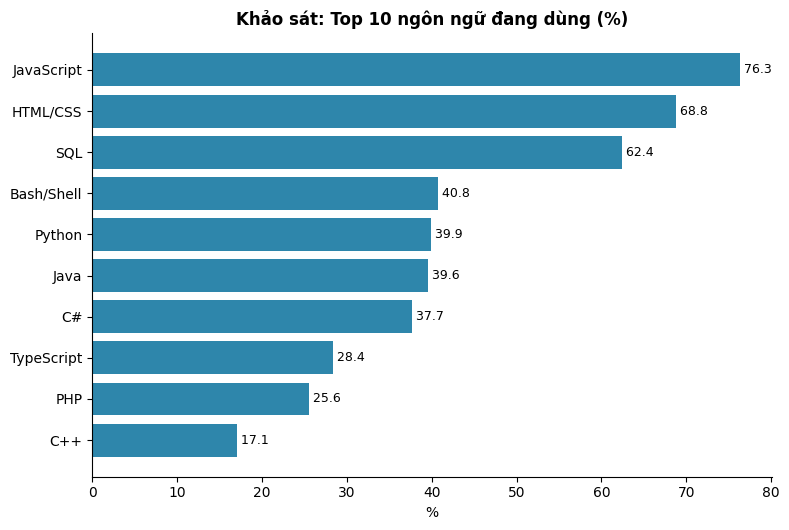

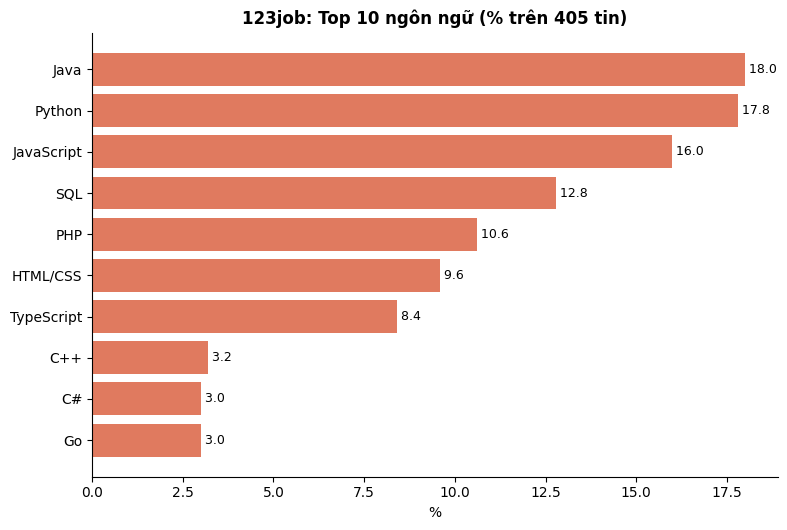

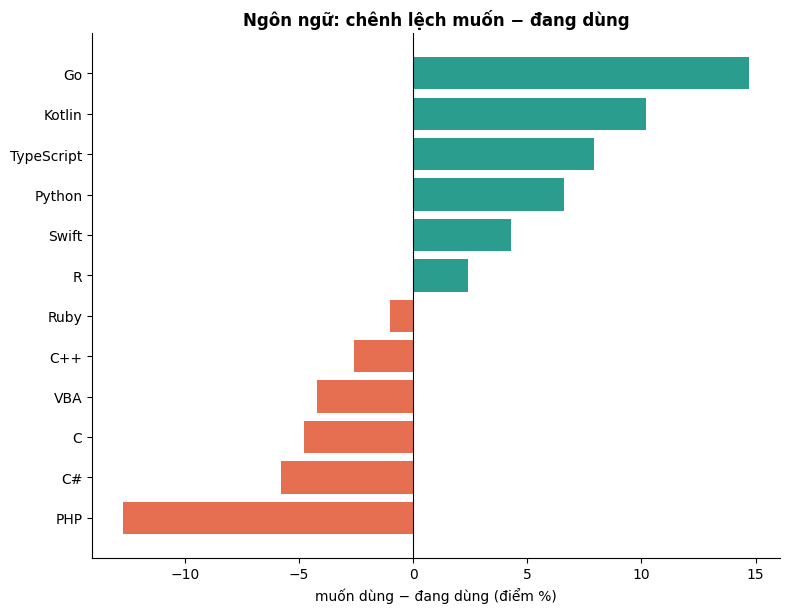

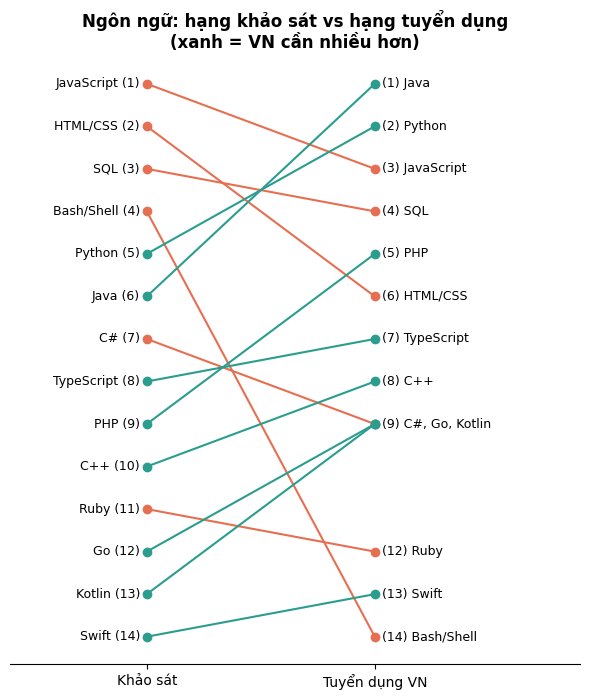

In [10]:
ve_thanh(lang["pct_worked"], "Khảo sát: Top 10 ngôn ngữ đang dùng (%)", "q1_lang_worked.png")
ve_thanh(job_lang, f"123job: Top 10 ngôn ngữ (% trên {TONG_TIN} tin)", "q1_lang_jobs.png", mau="#E07A5F")

def ve_chenh_lech(bang, tieu_de, file, n=12):
    d = bang[bang["pct_worked"] >= 5].sort_values("gap").tail(n)     # chỉ kỹ năng đủ phổ biến
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(d) + 1.2))
    ax.barh(d.index, d["gap"], color=["#2A9D8F" if g > 0 else "#E76F51" for g in d["gap"]])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(tieu_de, fontweight="bold"); ax.set_xlabel("muốn dùng − đang dùng (điểm %)")
    plt.tight_layout(); fig.savefig(HINH / file, dpi=150); plt.show()

def ve_so_hang(hang, tieu_de, file):
    fig, ax = plt.subplots(figsize=(6, 0.4 * len(hang) + 1.5))
    for ten, d in hang.iterrows():
        mau = "#2A9D8F" if d.rank_diff > 0 else ("#E76F51" if d.rank_diff < 0 else "grey")
        ax.plot([0, 1], [d.rank_survey, d.rank_jobs], marker="o", color=mau)
        ax.text(-0.03, d.rank_survey, f"{ten} ({int(d.rank_survey)})", ha="right", va="center", fontsize=9)
    for hang_td, nhom in hang.groupby("rank_jobs"):              # kỹ năng đồng hạng -> ghi chung 1 nhãn
        ax.text(1.03, hang_td, f"({int(hang_td)}) " + ", ".join(nhom.index), ha="left", va="center", fontsize=9)
    ax.invert_yaxis(); ax.set_xlim(-0.6, 1.9); ax.set_xticks([0, 1]); ax.set_xticklabels(["Khảo sát", "Tuyển dụng VN"])
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.set_title(tieu_de + "\n(xanh = VN cần nhiều hơn)", fontweight="bold")
    plt.tight_layout(); fig.savefig(HINH / file, dpi=150); plt.show()

ve_chenh_lech(lang, "Ngôn ngữ: chênh lệch muốn − đang dùng", "q1_lang_gap.png")
ve_so_hang(hang_lang, "Ngôn ngữ: hạng khảo sát vs hạng tuyển dụng", "q1_lang_rank_compare.png")

## Q2. Dạy database nào, ưu tiên SQL quan hệ hay NoSQL?
> **Quyết định:** chọn hệ quản trị CSDL cho giáo trình và tỷ trọng SQL/NoSQL.

### Q2.1 Phân loại & so sánh database
**🎯 Mục tiêu:** Bảng database: đang dùng, muốn dùng, chênh lệch, loại (quan hệ / NoSQL), % tin VN.

**❓ Vì sao làm bước này:** *CSDL quan hệ* (SQL) lưu dữ liệu dạng bảng có liên kết (MySQL, PostgreSQL…). *NoSQL* lưu kiểu khác (tài liệu, khóa–giá trị: MongoDB, Redis…). Tỷ trọng giữa 2 loại là quyết định giáo trình.

**🧠 Cách suy nghĩ:** Gắn loại bằng một từ điển nhỏ (`map`). Đọc 3 tín hiệu: hiện tại (đang dùng), xu hướng (chênh lệch), thị trường VN (hạng tin tuyển dụng).

**🔁 Dùng khi nào (trường hợp khác):** Gom mục chi tiết thành nhóm lớn: sản phẩm → ngành hàng.

In [11]:
QUAN_HE = {"MySQL", "PostgreSQL", "SQL Server", "SQLite", "Oracle", "MariaDB"}   # còn lại là NoSQL
db = dang_dung_vs_muon("database")
db["db_type"] = np.where(db.index.isin(QUAN_HE), "Quan hệ (SQL)", "NoSQL")
job_db = pct_tuyen_dung("database")
db = db.join(job_db.rename("pct_jobs")).fillna({"pct_jobs": 0})
hang_db, rho_db, p_db = so_sanh_hang(db["pct_worked"], job_db)
print("Mẫu số: đang dùng =", respondents["answered_database_worked"].sum(),
      "| muốn dùng =", respondents["answered_database_desire"].sum())
print(f"Spearman hạng (khảo sát vs tuyển dụng): rho = {rho_db:.2f}, p = {p_db:.3f}, n = {len(hang_db)}")
db

Mẫu số: đang dùng = 10945 | muốn dùng = 10356
Spearman hạng (khảo sát vs tuyển dụng): rho = 0.68, p = 0.030, n = 10


,pct_worked,pct_desire,gap,growth_ratio,db_type,pct_jobs
skill,,,,,,
MySQL,50.0,31.7,-18.3,0.63,Quan hệ (SQL),8.6
SQL Server,37.6,26.1,-11.5,0.69,Quan hệ (SQL),3.7
PostgreSQL,37.4,41.8,4.4,1.12,Quan hệ (SQL),9.1
SQLite,29.7,23.5,-6.2,0.79,Quan hệ (SQL),0.5
MongoDB,27.6,35.2,7.6,1.28,NoSQL,4.0
Redis,22.9,32.2,9.3,1.41,NoSQL,3.2
Elasticsearch,17.9,27.6,9.7,1.54,NoSQL,3.5
Oracle,15.9,8.4,-7.5,0.53,Quan hệ (SQL),2.2
MariaDB,15.6,13.4,-2.2,0.86,Quan hệ (SQL),0.5


### Q2.2 Ở cấp nhóm: bao nhiêu % dùng ít nhất 1 CSDL quan hệ / NoSQL?
**🎯 Mục tiêu:** Trả lời trực tiếp "SQL hay NoSQL" bằng % người/tin có dùng ít nhất 1 hệ mỗi loại.

**❓ Vì sao làm bước này:** Cộng % từng database sẽ ra số >100% (1 người dùng nhiều hệ). Đếm *người có ít nhất 1* mới đúng nghĩa "bao nhiêu người cần loại này".

**🧠 Cách suy nghĩ:** Gắn loại cho từng dòng → đếm số người/tin khác nhau theo loại → chia mẫu số.

**🔁 Dùng khi nào (trường hợp khác):** "Bao nhiêu khách mua ít nhất 1 sản phẩm thuộc nhóm X".

In [12]:
def ty_le_theo_loai(bang, cot_id, mau_so):
    b = bang.assign(db_type=np.where(bang["skill"].isin(QUAN_HE), "Quan hệ (SQL)", "NoSQL"))
    return (b.groupby("db_type")[cot_id].nunique() / mau_so * 100).round(1)

q2_nhom = pd.DataFrame({
    "khảo sát – đang dùng": ty_le_theo_loai(survey_skills.query("skill_group=='database' and status=='worked_with'"),
                                            "respondent_id", respondents["answered_database_worked"].sum()),
    "khảo sát – muốn dùng": ty_le_theo_loai(survey_skills.query("skill_group=='database' and status=='desire_next_year'"),
                                            "respondent_id", respondents["answered_database_desire"].sum()),
    "tuyển dụng VN (% tin)": ty_le_theo_loai(job_skills.query("skill_group=='database'"), "job_id", TONG_TIN),
})
q2_nhom

,khảo sát – đang dùng,khảo sát – muốn dùng,tuyển dụng VN (% tin)
db_type,,,
NoSQL,55.9,70.0,8.6
Quan hệ (SQL),93.5,83.3,16.3


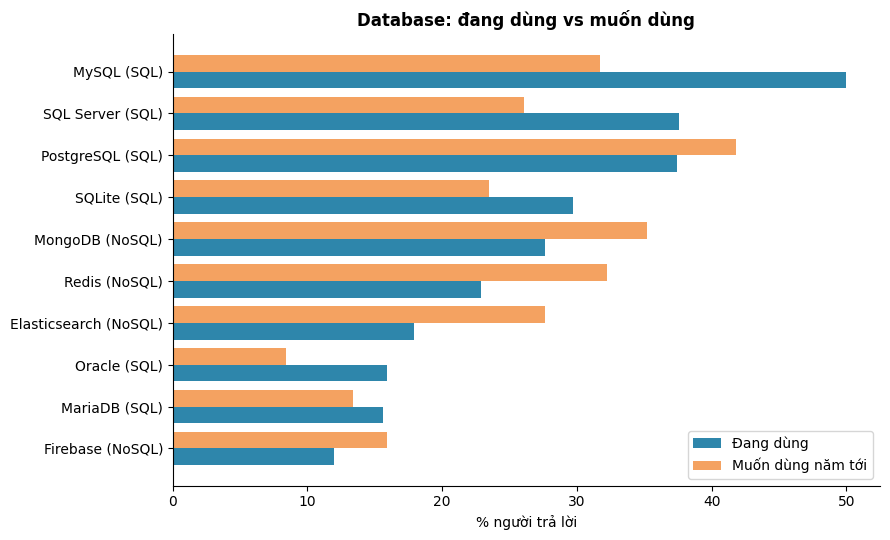

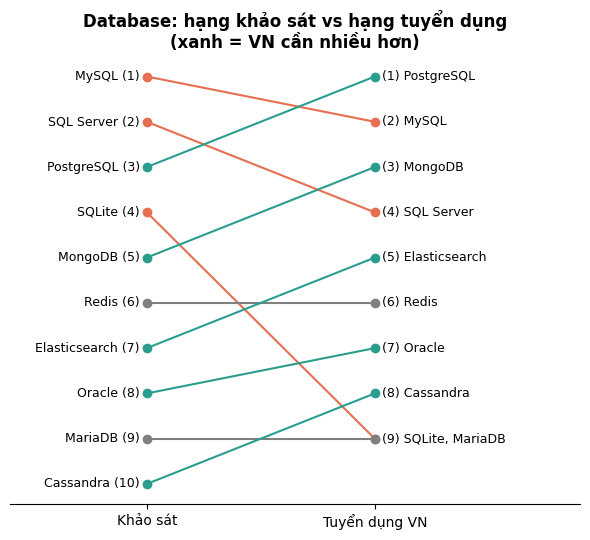

In [13]:
fig, ax = plt.subplots(figsize=(9, 5.5))
d = db.head(10)[::-1]
y = np.arange(len(d))
ax.barh(y - 0.2, d["pct_worked"], height=0.4, label="Đang dùng", color="#2E86AB")
ax.barh(y + 0.2, d["pct_desire"], height=0.4, label="Muốn dùng năm tới", color="#F4A261")
ax.set_yticks(y); ax.set_yticklabels([f"{t} ({'SQL' if t in QUAN_HE else 'NoSQL'})" for t in d.index])
ax.set_xlabel("% người trả lời"); ax.legend(); ax.set_title("Database: đang dùng vs muốn dùng", fontweight="bold")
plt.tight_layout(); fig.savefig(HINH / "q2_db_worked_vs_desire.png", dpi=150); plt.show()
ve_so_hang(hang_db, "Database: hạng khảo sát vs hạng tuyển dụng", "q2_db_rank_compare.png")

## Q3. Chuẩn hóa IDE nào cho phòng lab?
> **Quyết định:** cài phần mềm nào trên máy lab, viết giáo trình theo IDE nào.

### Q3.1 IDE phổ biến (chỉ khảo sát)
**🎯 Mục tiêu:** Top IDE (phần mềm để viết code) và % người dùng.

**❓ Vì sao làm bước này:** Tin tuyển dụng hầu như không ghi IDE → chỉ dùng khảo sát, và nói rõ giới hạn này.

**🧠 Cách suy nghĩ:** Mẫu số = người đã trả lời câu IDE (`answered_ide`). Xem cả IDE chuyên cho một ngôn ngữ (IntelliJ – Java, PyCharm/Jupyter – Python) để ghép với khóa học ở Q1.

**🔁 Dùng khi nào (trường hợp khác):** Chọn công cụ chuẩn cho cả nhóm/công ty.

Mẫu số: 11369
skill
Visual Studio Code    58.4
Visual Studio         35.4
Notepad++             30.2
IntelliJ              27.2
Vim                   26.7
Sublime Text          23.2
Android Studio        14.9
PyCharm               12.7
Eclipse               12.1
Atom                  11.6
Xcode                  9.1
Jupyter                8.8
Name: respondent_id, dtype: float64


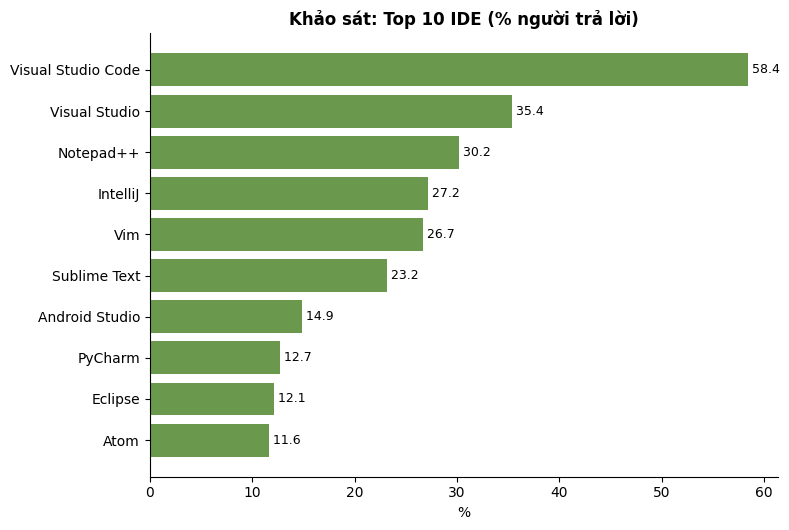

In [14]:
ide = pct_khao_sat("ide", "worked_with")
print("Mẫu số:", respondents["answered_ide"].sum())
print(ide.head(12))
ve_thanh(ide, "Khảo sát: Top 10 IDE (% người trả lời)", "q3_ide.png", mau="#6A994E")

## Q4. Kỹ năng mới nổi nào nên đầu tư, nhắm nhóm học viên nào?
> **Quyết định:** mở khóa mới năm tới về kỹ năng gì, đưa vào lộ trình cho ai.

### Q4.1 Platform & framework: đang dùng vs muốn dùng
**🎯 Mục tiêu:** Tìm kỹ năng có chênh lệch và tỷ lệ tăng (muốn ÷ đang dùng) cao.

**❓ Vì sao làm bước này:** Kỹ năng "muốn học" nhiều hơn hẳn "đang dùng" = nhu cầu học sắp tăng → cơ hội mở khóa.

**🧠 Cách suy nghĩ:** Chỉ xét kỹ năng đang dùng ≥ 5% (tránh tỷ lệ ảo: 1% → 3% = ×3). Xếp theo **chênh lệch** (bao nhiêu người thêm), xem kèm **tỷ lệ tăng** (tăng nhanh đến đâu).

**🔁 Dùng khi nào (trường hợp khác):** Tìm sản phẩm/kênh đang tăng trưởng.

In [15]:
plat = dang_dung_vs_muon("platform_tool").assign(group="platform_tool")
fw = dang_dung_vs_muon("framework").assign(group="framework")
noi_len = pd.concat([plat, fw])
noi_len = noi_len[noi_len["pct_worked"] >= 5].sort_values("gap", ascending=False)

# Gắn % tuyển dụng VN (cùng tên kỹ năng); Node.js bỏ vì 2 nguồn hiểu khác nhau
job_all = job_skills.groupby("skill")["job_id"].nunique() / TONG_TIN * 100
noi_len["pct_jobs_vn"] = noi_len.index.map(job_all).fillna(0).round(1)
noi_len.loc[noi_len.index.isin(BO_KHI_SO_SANH), "pct_jobs_vn"] = np.nan
noi_len.head(12)

,pct_worked,pct_desire,gap,growth_ratio,group,pct_jobs_vn
skill,,,,,,
Kubernetes,11.3,29.5,18.2,2.61,platform_tool,7.9
TensorFlow,7.2,23.5,16.3,3.26,framework,0.0
Vue.js,13.5,28.5,15.0,2.11,framework,5.7
Docker,39.8,53.5,13.7,1.34,platform_tool,9.4
React,30.0,42.7,12.7,1.42,framework,21.2
React Native,9.2,21.1,11.9,2.29,framework,0.0
Google Cloud,13.2,22.1,8.9,1.67,platform_tool,5.4
Raspberry Pi,14.7,23.3,8.6,1.59,platform_tool,0.0
AWS,32.7,40.9,8.2,1.25,platform_tool,11.4


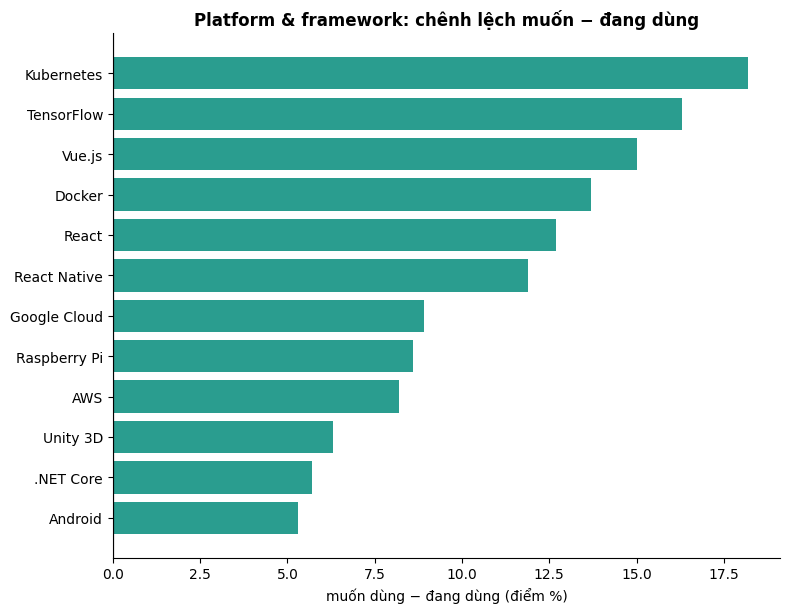

In [16]:
ve_chenh_lech(noi_len.drop(columns="group"), "Platform & framework: chênh lệch muốn − đang dùng", "q4_emerging_gap.png")

### Q4.2 Chọn "kỹ năng mới nổi số 1"
**🎯 Mục tiêu:** Chọn 1 kỹ năng làm đại diện để phân tích nhóm học viên.

**❓ Vì sao làm bước này:** Cần một kỹ năng cụ thể để trả lời "nhắm ai".

**🧠 Cách suy nghĩ:** Quy tắc: chênh lệch lớn nhất **và** có xuất hiện trong tin tuyển dụng VN (thị trường VN có cần thật). Code tự chọn, không chọn tay.

**🔁 Dùng khi nào (trường hợp khác):** Chọn "sản phẩm chủ lực" theo tiêu chí rõ ràng.

In [17]:
ung_vien = noi_len[noi_len["pct_jobs_vn"] > 0]
KY_NANG_MOI = ung_vien.index[0]                     # kỹ năng có chênh lệch lớn nhất & có trong tin VN
NHOM_KY_NANG = ung_vien["group"].iloc[0]
print("Kỹ năng mới nổi được chọn:", KY_NANG_MOI, "| nhóm:", NHOM_KY_NANG)
print(ung_vien.loc[KY_NANG_MOI, ["pct_worked", "pct_desire", "gap", "growth_ratio", "pct_jobs_vn"]])

Kỹ năng mới nổi được chọn: Kubernetes | nhóm: platform_tool
pct_worked      11.30
pct_desire      29.50
gap             18.20
growth_ratio     2.61
pct_jobs_vn      7.90
Name: Kubernetes, dtype: float64


### Q4.3 Nhóm nào muốn học kỹ năng này nhất? (đo trực tiếp)
**🎯 Mục tiêu:** % muốn dùng kỹ năng mới nổi theo nhóm kinh nghiệm.

**❓ Vì sao làm bước này:** Đây là thước đo **trực tiếp** cho câu "nhắm người mới hay người có kinh nghiệm" – tốt hơn chỉ nhìn lương.

**🧠 Cách suy nghĩ:** Mẫu số = người trong nhóm đó đã trả lời câu "muốn dùng" của nhóm kỹ năng này. Bỏ nhóm `Unknown`.

**🔁 Dùng khi nào (trường hợp khác):** % khách quan tâm sản phẩm theo độ tuổi/khu vực.

In [18]:
THU_TU_NHOM = ["0-2 nam", "3-5 nam", "6-10 nam", "11-20 nam", "Tren 20 nam"]
co_muon = respondents[CO_TRA_LOI[(NHOM_KY_NANG, "desire_next_year")]] == 1
nguoi = respondents.loc[co_muon & respondents["exp_group"].isin(THU_TU_NHOM), ["respondent_id", "exp_group"]].copy()
ids_muon = set(survey_skills.query("skill == @KY_NANG_MOI and status == 'desire_next_year'")["respondent_id"])
ids_dang = set(survey_skills.query("skill == @KY_NANG_MOI and status == 'worked_with'")["respondent_id"])
nguoi["muon"] = nguoi["respondent_id"].isin(ids_muon)
nguoi["dang_dung"] = nguoi["respondent_id"].isin(ids_dang)

theo_nhom = (nguoi.groupby("exp_group")[["dang_dung", "muon"]].mean() * 100).round(1).reindex(THU_TU_NHOM)
theo_nhom["so_nguoi"] = nguoi["exp_group"].value_counts().reindex(THU_TU_NHOM)
theo_nhom.columns = ["% đang dùng", "% muốn dùng", "số người"]
theo_nhom

,% đang dùng,% muốn dùng,số người
exp_group,,,
0-2 nam,7.4,23.3,2220
3-5 nam,11.1,28.9,3220
6-10 nam,13.2,33.1,2786
11-20 nam,12.7,32.7,2030
Tren 20 nam,11.2,27.7,582


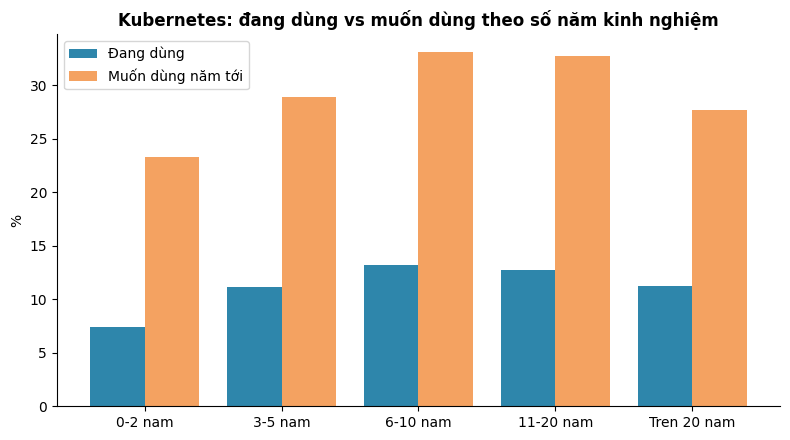

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(theo_nhom))
ax.bar(x - 0.2, theo_nhom["% đang dùng"], 0.4, label="Đang dùng", color="#2E86AB")
ax.bar(x + 0.2, theo_nhom["% muốn dùng"], 0.4, label="Muốn dùng năm tới", color="#F4A261")
ax.set_xticks(x); ax.set_xticklabels(theo_nhom.index); ax.set_ylabel("%"); ax.legend()
ax.set_title(f"{KY_NANG_MOI}: đang dùng vs muốn dùng theo số năm kinh nghiệm", fontweight="bold")
plt.tight_layout(); fig.savefig(HINH / "q4_emerging_by_exp.png", dpi=150); plt.show()

### Q4.4 Kiểm định Chi-bình-phương + Cramér's V
**🎯 Mục tiêu:** Kiểm tra khác biệt giữa các nhóm kinh nghiệm có thật hay do ngẫu nhiên.

**❓ Vì sao làm bước này:** Để bảo vệ kết luận "nhắm nhóm X" bằng thống kê.

**🧠 Cách suy nghĩ:** Chi-bình-phương dùng cho **2 biến dạng nhóm** (nhóm kinh nghiệm × muốn/không muốn). **p < 0.05** = khác biệt khó do ngẫu nhiên. Mẫu hàng nghìn người thì khác biệt nhỏ cũng có p nhỏ → xem **Cramér's V** (0–1): < 0.1 rất yếu, 0.1–0.3 yếu–vừa, > 0.3 mạnh.

**🔁 Dùng khi nào (trường hợp khác):** Giới tính × lựa chọn sản phẩm, khu vực × có mua hay không.

In [20]:
bang_cheo = pd.crosstab(nguoi["exp_group"], nguoi["muon"]).reindex(THU_TU_NHOM)
bang_cheo.columns = ["Không muốn", "Muốn"]
chi2, p_chi, bac_tu_do, _ = stats.chi2_contingency(bang_cheo)
cramer_v = np.sqrt(chi2 / (bang_cheo.values.sum() * (min(bang_cheo.shape) - 1)))
display(bang_cheo)
print(f"Chi2 = {chi2:.1f}, bậc tự do = {bac_tu_do}, p = {p_chi:.2e}, Cramér's V = {cramer_v:.3f}")

,Không muốn,Muốn
exp_group,,
0-2 nam,1703,517
3-5 nam,2288,932
6-10 nam,1864,922
11-20 nam,1367,663
Tren 20 nam,421,161


Chi2 = 69.7, bậc tự do = 4, p = 2.64e-14, Cramér's V = 0.080


### Q4.5 Kinh nghiệm và lương (Spearman, trung vị)
**🎯 Mục tiêu:** Xem kinh nghiệm tăng thì lương tăng đến đâu – bối cảnh cho việc chọn đối tượng học viên.

**❓ Vì sao làm bước này:** Học viên mới cần biết "học xong, đi làm vài năm thì thu nhập ra sao"; nhóm có kinh nghiệm cần lý do để học nâng cao.

**🧠 Cách suy nghĩ:** Lương có vài giá trị rất lớn → dùng **trung vị (median)** thay trung bình, và **Spearman** (so theo thứ hạng, ít bị giá trị khủng làm lệch). ⚠️ Tương quan không phải nguyên nhân; lương còn phụ thuộc quốc gia.

**🔁 Dùng khi nào (trường hợp khác):** Giờ học vs điểm, chi phí quảng cáo vs doanh thu.

In [21]:
cap = respondents[["years_code_pro", "annual_comp_usd"]].dropna()
rho_luong, p_luong = stats.spearmanr(cap["years_code_pro"], cap["annual_comp_usd"])
print(f"n = {len(cap)} | Spearman rho = {rho_luong:.2f}, p = {'< 0.001' if p_luong < 0.001 else round(p_luong, 3)}")
luong = respondents[respondents["exp_group"].isin(THU_TU_NHOM)].groupby("exp_group")["annual_comp_usd"] \
    .agg(so_nguoi="count", trung_vi="median", trung_binh="mean").reindex(THU_TU_NHOM).round(0)
luong

n = 10252 | Spearman rho = 0.41, p = < 0.001


,so_nguoi,trung_vi,trung_binh
exp_group,,,
0-2 nam,2097,29385.0,59898.0
3-5 nam,3082,46976.0,83463.0
6-10 nam,2637,63016.0,102069.0
11-20 nam,1890,83868.0,127615.0
Tren 20 nam,546,103243.0,143509.0


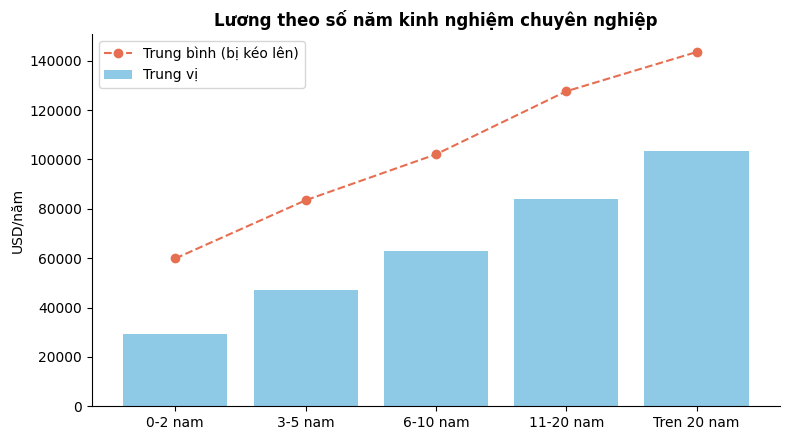

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(luong.index, luong["trung_vi"], color="#8ECAE6", label="Trung vị")
ax.plot(luong.index, luong["trung_binh"], "o--", color="#E76F51", label="Trung bình (bị kéo lên)")
ax.set_ylabel("USD/năm"); ax.legend(); ax.set_title("Lương theo số năm kinh nghiệm chuyên nghiệp", fontweight="bold")
plt.tight_layout(); fig.savefig(HINH / "q4_salary_by_exp.png", dpi=150); plt.show()

## 5. Tóm tắt số liệu & lưu bảng cho slide

### 5.1 In các con số chính & lưu `eda_summary.xlsx`
**🎯 Mục tiêu:** Gom kết quả 4 câu hỏi vào một chỗ để viết insight và dán vào slide/Power BI.

**❓ Vì sao làm bước này:** Insight phải dựa trên số thật. Lưu bảng giúp không phải chạy lại.

**🧠 Cách suy nghĩ:** Mỗi câu hỏi 1 sheet; dùng `openpyxl` (đã có sẵn) để ghi Excel.

**🔁 Dùng khi nào (trường hợp khác):** Cuối mọi phân tích, trước khi viết báo cáo.

In [23]:
def top(s, n=5):
    return ", ".join(f"{k} {v:.1f}%" for k, v in s.head(n).items())
print("Q1 đang dùng :", top(lang["pct_worked"]))
print("Q1 muốn dùng :", top(lang["pct_desire"].sort_values(ascending=False)))
print("Q1 tuyển dụng:", top(job_lang))
print("Q1 chênh lệch:", top(lang[lang.pct_worked >= 5]["gap"].sort_values(ascending=False)).replace("%", " điểm"))
print(f"Q1 Spearman hạng: rho={rho_lang:.2f}, p={p_lang:.3f}")
print("Q2 đang dùng :", top(db["pct_worked"]))
print("Q2 muốn dùng :", top(db["pct_desire"].sort_values(ascending=False)))
print("Q2 tuyển dụng:", top(job_db))
print(f"Q2 Spearman hạng: rho={rho_db:.2f}, p={p_db:.3f}")
print("Q3 IDE       :", top(ide))
print("Q4 mới nổi   :", ", ".join(f"{k} +{r.gap} (x{r.growth_ratio})" for k, r in noi_len.head(5).iterrows()))
print(f"Q4 {KY_NANG_MOI}: Chi2={chi2:.1f}, p={p_chi:.2e}, V={cramer_v:.3f} | lương: rho={rho_luong:.2f}, p<0.001")

with pd.ExcelWriter("eda_summary.xlsx", engine="openpyxl") as w:
    q1.to_excel(w, sheet_name="Q1_languages")
    hang_lang.to_excel(w, sheet_name="Q1_rank_compare")
    db.to_excel(w, sheet_name="Q2_databases")
    q2_nhom.to_excel(w, sheet_name="Q2_sql_vs_nosql")
    ide.rename("pct_users").to_frame().to_excel(w, sheet_name="Q3_ide")
    noi_len.to_excel(w, sheet_name="Q4_emerging")
    theo_nhom.to_excel(w, sheet_name="Q4_by_exp_group")
    luong.to_excel(w, sheet_name="Q4_salary")
print("\nĐã lưu eda_summary.xlsx và ảnh trong figures/:", sorted(p.name for p in HINH.glob("*.png")))

Q1 đang dùng : JavaScript 76.3%, HTML/CSS 68.8%, SQL 62.4%, Bash/Shell 40.8%, Python 39.9%
Q1 muốn dùng : JavaScript 58.9%, HTML/CSS 47.3%, Python 46.5%, SQL 44.5%, TypeScript 36.3%
Q1 tuyển dụng: Java 18.0%, Python 17.8%, JavaScript 16.0%, SQL 12.8%, PHP 10.6%
Q1 chênh lệch: Go 14.7 điểm, Kotlin 10.2 điểm, TypeScript 7.9 điểm, Python 6.6 điểm, Swift 4.3 điểm
Q1 Spearman hạng: rho=0.56, p=0.038
Q2 đang dùng : MySQL 50.0%, SQL Server 37.6%, PostgreSQL 37.4%, SQLite 29.7%, MongoDB 27.6%
Q2 muốn dùng : PostgreSQL 41.8%, MongoDB 35.2%, Redis 32.2%, MySQL 31.7%, Elasticsearch 27.6%
Q2 tuyển dụng: PostgreSQL 9.1%, MySQL 8.6%, MongoDB 4.0%, SQL Server 3.7%, Elasticsearch 3.5%
Q2 Spearman hạng: rho=0.68, p=0.030
Q3 IDE       : Visual Studio Code 58.4%, Visual Studio 35.4%, Notepad++ 30.2%, IntelliJ 27.2%, Vim 26.7%
Q4 mới nổi   : Kubernetes +18.2 (x2.61), TensorFlow +16.3 (x3.26), Vue.js +15.0 (x2.11), Docker +13.7 (x1.34), React +12.7 (x1.42)
Q4 Kubernetes: Chi2=69.7, p=2.64e-14, V=0.080 | lư

## 6. Insight rút ra (từ số liệu thật của notebook này)

**Bối cảnh mẫu:** 11.398 người trả lời khảo sát Stack Overflow (toàn cầu; chỉ 12 người VN nên *không* phân tích VN trong khảo sát) và 405 tin IT trên 123job.vn (304 tin = 75% có nhắc ít nhất 1 kỹ năng).

**Q1 – Ngôn ngữ.** Đang dùng nhiều nhất: JavaScript 76,3%, HTML/CSS 68,8%, SQL 62,4%, Bash/Shell 40,8%, Python 39,9%. Tin tuyển dụng VN: Java 18,0%, Python 17,8%, JavaScript 16,0%, SQL 12,8%, PHP 10,6%. Hai bảng xếp hạng khá giống nhau (Spearman rho = 0,56, p = 0,038, 14 ngôn ngữ), nhưng **VN đề cao Java (hạng 6 → 1), Python (5 → 2), PHP (9 → 5)** và ít nhắc Bash/Shell (4 → 14). Python là ngôn ngữ phổ biến duy nhất vừa ở top tuyển dụng vừa **đang tăng** (muốn dùng 46,5% > đang dùng 39,9%). Tăng mạnh nhất: Go (+14,7 điểm), Kotlin (+10,2), TypeScript (+7,9), nhưng Go/Kotlin mới có ~3% tin VN.

**Q2 – Database.** 93,5% người trả lời đang dùng ít nhất 1 CSDL quan hệ, so với 55,9% cho NoSQL; nhưng ở cột *muốn dùng*, NoSQL lên 70,0% (quan hệ giảm còn 83,3%). MySQL đang dùng nhiều nhất (50,0%) nhưng giảm (−18,3 điểm); **PostgreSQL đứng #1 ở cả "muốn dùng" (41,8%) và tin VN (9,1%)**. NoSQL đang tăng: Elasticsearch +9,7, Redis +9,3, MongoDB +7,6 điểm. Ở VN, 16,3% tin nêu tên một CSDL quan hệ, chỉ 8,6% nêu NoSQL. Hạng 2 nguồn giống nhau (rho = 0,68, p = 0,030, 10 hệ).

**Q3 – IDE (chỉ khảo sát).** Visual Studio Code 58,4%, Visual Studio 35,4%, Notepad++ 30,2%, IntelliJ 27,2%, Vim 26,7%.

**Q4 – Kỹ năng mới nổi & nhóm học viên.** Chênh lệch lớn nhất (trong các kỹ năng đang dùng ≥ 5%): **Kubernetes +18,2 điểm (11,3% → 29,5%, ×2,6)**, TensorFlow +16,3, Vue.js +15,0, Docker +13,7, React +12,7. Kubernetes có trong 7,9% tin VN, Docker 9,4%, AWS 11,4%; React là kỹ năng được nhắc nhiều nhất trong tin VN (21,2%). Theo kinh nghiệm, người muốn học Kubernetes cao nhất ở nhóm 6–10 năm (33,1%) và 11–20 năm (32,7%), thấp nhất ở 0–2 năm (23,3%). Khác biệt có ý nghĩa thống kê (Chi² = 69,7, p < 0,001) nhưng **rất yếu (Cramér's V = 0,08)** → nhu cầu có ở mọi nhóm, không riêng nhóm nào. Lương tăng theo kinh nghiệm ở mức vừa (Spearman rho = 0,41): trung vị 29.385 USD (0–2 năm) → 46.976 (3–5) → 63.016 (6–10) → 103.243 (> 20 năm); trung bình cao hơn hẳn trung vị vì có vài mức lương rất cao.

### 3 khuyến nghị cho Quản lý đào tạo
1. **Khóa lõi = SQL + Web nền tảng (HTML/CSS, JavaScript) + 1 nhánh backend Java hoặc Python.** Đây là các ngôn ngữ vừa phổ biến toàn cầu vừa ở top 4 tuyển dụng VN; Python còn đang tăng. CSDL: dạy **quan hệ trước (lấy PostgreSQL làm chính, MySQL làm phụ)**, rồi thêm một module NoSQL (MongoDB + Redis), vì nhu cầu NoSQL đang tăng nhưng tin VN vẫn nghiêng về SQL. Máy lab chuẩn hóa **VS Code**, thêm **IntelliJ** cho nhánh Java.
2. **Mở mới 2 khóa:** (a) **DevOps/Cloud: Docker → Kubernetes → AWS**, nhóm có chênh lệch muốn − đang dùng lớn nhất và đã có trong tin VN; (b) **Front-end hiện đại: TypeScript + React**. Theo dõi thêm Go, Kotlin, TensorFlow: đang được quan tâm nhiều nhưng tin VN còn ít (TensorFlow: 0 tin).
3. **Đối tượng:** khóa Kubernetes/DevOps nên thiết kế như **khóa nâng cao cho người đã đi làm 3–10 năm** (2 nhóm đông nhất, mức quan tâm 29–33%), kèm **lộ trình cho fresher** (Docker cơ bản trước), vì ngay cả nhóm 0–2 năm cũng có 23% muốn học (V = 0,08: không nên loại nhóm nào).

### ⚠️ Lưu ý khi bảo vệ
- Khảo sát là dữ liệu **toàn cầu** của Stack Overflow và đã cũ vài năm; người VN chỉ có 12 người → nhu cầu VN lấy từ 123job.
- Kỹ năng trong tin được rút bằng **so khớp từ khóa** (gần đúng); 25% tin không nhắc kỹ năng nào. 0% có thể là do từ điển từ khóa thiếu kỹ năng đó chứ không hẳn là không có nhu cầu. Chỉ 405 tin từ 1 trang web → so theo **thứ hạng**, không so % tuyệt đối.
- Node.js bị loại khỏi mọi phép so sánh giữa 2 nguồn (2 nguồn định nghĩa khác nhau).
- Tương quan ≠ nhân quả (kinh nghiệm–lương còn phụ thuộc quốc gia, vị trí). Với mẫu lớn, p nhỏ là chuyện thường → luôn xem kèm độ mạnh (rho, Cramér's V).